# Analyze and compare metrics

In [1]:
import numpy as np
import pandas as pd
import scanpy as sc
import anndata as ad
import scipy
from scipy.cluster.hierarchy import linkage, leaves_list
import seaborn as sns
from pathlib import Path
import matplotlib.pyplot as plt
import sklearn
from itertools import combinations

from sklearn.covariance import MinCovDet
from scipy.stats import chi2
import math

import matplotlib.font_manager as font_manager

font_manager.fontManager.addfont('/ubc/cs/research/beaver/projects/yinian/fonts/arial.ttf')
prop = font_manager.FontProperties(fname='/ubc/cs/research/beaver/projects/yinian/fonts/arial.ttf')

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = prop.get_name()

import os
import sys
sys.path.insert(0, '/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scib/')
sys.path.insert(0, '/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scripts/project_utils/')
os.environ["R_HOME"] = "/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/R"

mm_s = pd.read_csv('../scib/scib/resources/s_genes_tirosh.txt', header=None, index_col=0).index.to_numpy()
mm_g2m = pd.read_csv('../scib/scib/resources/g2m_genes_tirosh.txt', header=None, index_col=0).index.to_numpy()

hg_s = pd.read_csv('../scib/scib/resources/s_genes_tirosh_hm.txt', header=None, index_col=0).index.to_numpy()
hg_g2m = pd.read_csv('../scib/scib/resources/g2m_genes_tirosh_hm.txt', header=None, index_col=0).index.to_numpy()

/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/python3.10/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


In [2]:
import scib
from scib.metrics import *
from analysis_helpers import *

In [3]:
EMB_KEY = 'X_integration'

In [4]:
df_full = pd.read_csv('../results/spreadsheets/metric_values_v14.csv', index_col=0)
# df_full = pd.read_csv('../results/spreadsheets/augmented_metrics_v2.csv', index_col=0)

df_full['Dataset'] = df_full['Dataset'].replace({
    'nph_cerebellum': 'nhp_cerebellum',
    'nph_liver': 'nhp_liver'
})
pivoted_df = df_full.pivot(index=['Dataset', 'Integration'], columns='Metric', values='Value')

# Access to the integrated data
runs = pd.read_csv('../results/spreadsheets/all_integrations.csv')

In [5]:
cvs = df_full[df_full['Integration'] != 'oneBigBlob-1'].pivot(index=['Dataset', 'Integration'], columns='Metric', values="Value").groupby('Dataset')[df_full.Metric.unique()].apply(
    lambda x: x.std() / x.mean().abs()
).reset_index()
mean_cv_per_metric = cvs[df_full.Metric.unique()].mean().sort_values(ascending=False)

## Compare pairs of metrics

Compute the Spearman correlation between metrics

In [6]:
metric_a = 'basw'
metric_b = 'kbet'

dataset_corrs = pivoted_df.groupby('Dataset').apply(
    lambda x: x[metric_a].corr(x[metric_b], method='spearman')
).reset_index(name='Spearman_Correlation').dropna()
print(dataset_corrs['Spearman_Correlation'].median())
# dataset_corrs.to_csv(f'../results/spreadsheets/{metric_a}_{metric_b}_corr.csv', index=False)
dataset_corrs.sort_values('Spearman_Correlation')

0.5241935483870969


,Dataset,Spearman_Correlation
21,pan_cancer_dc,-0.540769
7,human_lung,-0.045658
4,human_eoe,-0.018910
5,human_fetal_gut,-0.008403
17,neurips_bmmc,0.114272
6,human_heart,0.233551
24,seurat_pbmc,0.249644
25,tabula_muris_lung,0.365962
8,human_pancreas,0.377935
10,human_retina_organoid_tissue,0.389706


Plot the Spearman correlation between two metrics as a boxplot, which each dot representing a dataset.

/tmp/ipykernel_3678591/3279839048.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(
/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/python3.10/site-packages/seaborn/categorical.py:700: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


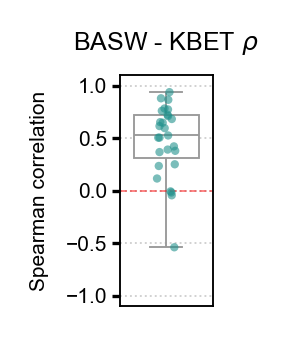

In [7]:
with plt.rc_context({'figure.dpi': 300}):
    fig, ax = plt.subplots(figsize=(.4, 1))

    sns.stripplot(
        data=dataset_corrs, 
        y='Spearman_Correlation', 
        jitter=True,
        size=2, 
        alpha=0.6, 
        palette='viridis'
    )

    sns.boxplot(
        data=dataset_corrs, 
        y='Spearman_Correlation', 
        whis=np.inf, 
        color='white', 
        width=0.7,
        linewidth=.45
    )

    plt.axhline(0, color='red', linestyle='--', alpha=0.5, linewidth=0.45)
    ax.tick_params(axis='both', which='major', width=.8, length=2, labelsize=5, pad=1)
    for spine in ax.spines.values():
        spine.set_linewidth(0.45)
    plt.title(f'{metric_a.upper()} - {metric_b.upper()} $\\rho$', fontsize=6)
    plt.ylabel('Spearman correlation', fontsize=5)
    plt.ylim(-1.1, 1.1)
    plt.grid(axis='y', linestyle=':', alpha=0.6, linewidth=0.45)
    plt.xticks([])
#     plt.savefig(f'../publication_figures/{metric_a}_{metric_b}_corr_box.png', dpi=300, bbox_inches='tight')

    plt.show()

Plot a scatterplot comparing metrics on each dataset, with each dot being an integration.

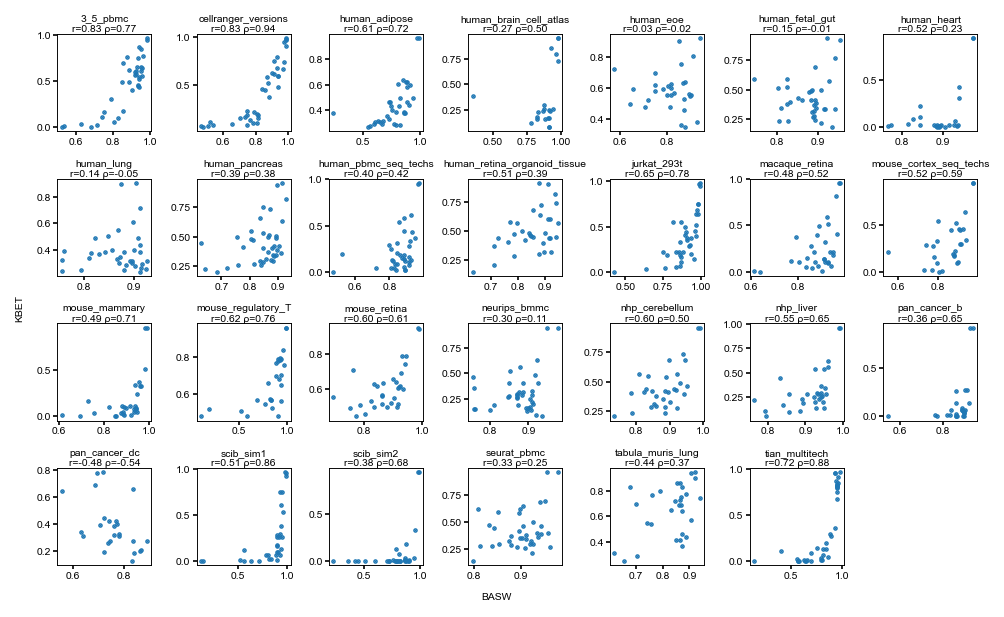

In [8]:
datasets = dataset_corrs['Dataset'].unique()
n_datasets = len(datasets)

n_cols = 7
n_rows = math.ceil(n_datasets / n_cols)

with plt.rc_context({'figure.dpi': 150}):
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(6.5, 4), constrained_layout=True)

    axes_flat = axes.flatten()

    for i, ds_name in enumerate(datasets):
        ax = axes_flat[i]

        sub = df_full[(df_full.Metric.isin([metric_a, metric_b])) & (df_full.Dataset == ds_name)]

        ds_pivoted = sub.pivot(index='Integration', columns='Metric', values='Value').dropna(subset=[metric_a, metric_b])

        x = ds_pivoted[metric_a].to_numpy()
        y = ds_pivoted[metric_b].to_numpy()

        ax.tick_params(axis='both', which='major', width=.8, length=2, labelsize=5, pad=1)
        for spine in ax.spines.values():
            spine.set_linewidth(0.45)
        pearson_r = scipy.stats.pearsonr(x, y).statistic
        spearman_rho = scipy.stats.spearmanr(x, y).statistic

        ax.scatter(x, y, alpha=1, s=.5)
        ax.set_title(f'{ds_name}\nr={pearson_r:.2f} ρ={spearman_rho:.2f}', fontsize=5, pad=0.5)

    fig.supxlabel(metric_a.upper(), fontweight='bold', fontsize=5)
    fig.supylabel(metric_b.upper(), fontweight='bold', fontsize=5)

    for j in range(i + 1, len(axes_flat)):
        axes_flat[j].axis('off')

#     plt.savefig(f'../publication_figures/{metric_a}_{metric_b}_corr.png', dpi=250, bbox_inches='tight')
    plt.show()

Plot the Spearman correlation between two metrics per dataset as a bar graph.

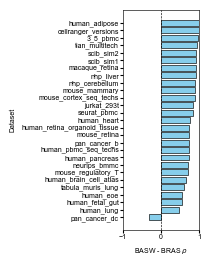

In [125]:
datasets = dataset_corrs['Dataset'].unique()
ds_names = []
rhos = []

for i, ds_name in enumerate(datasets):
    sub = df_full[(df_full.Metric.isin([metric_a, metric_b])) & (df_full.Dataset == ds_name)]
    ds_pivoted = sub.pivot(index='Integration', columns='Metric', values='Value').dropna(subset=[metric_a, metric_b])

    x = ds_pivoted[metric_a].to_numpy()
    y = ds_pivoted[metric_b].to_numpy()
    ds_names.append(ds_name)
    rhos.append(scipy.stats.spearmanr(x, y).statistic)

plot_df = pd.DataFrame({'Dataset': ds_names, 'Rho': rhos}).sort_values(by='Rho')

fig, ax = plt.subplots(1, 1, figsize=(2.5,3))

plt.barh(plot_df['Dataset'], plot_df['Rho'], color='skyblue', edgecolor='black', linewidth=0.45)
ax.set_xlim(-1, 1)
plt.axvline(0, color='black', linewidth=.45, linestyle='--')
ax.tick_params(axis='both', which='major', width=.8, length=2, labelsize=5, pad=1)
for spine in ax.spines.values():
    spine.set_linewidth(0.45)
plt.xlabel(f"{metric_a.upper()} - {metric_b.upper()} $\\rho$", fontsize=5)
plt.ylabel('Dataset', fontsize=5)

plt.tight_layout()
# plt.savefig(f'../publication_figures/{metric_a}_{metric_b}_corr_bar.png', dpi=250, bbox_inches='tight')
plt.show()

Plot a kernel density estimation plot of the metric values for `metric_a` on all datasets.

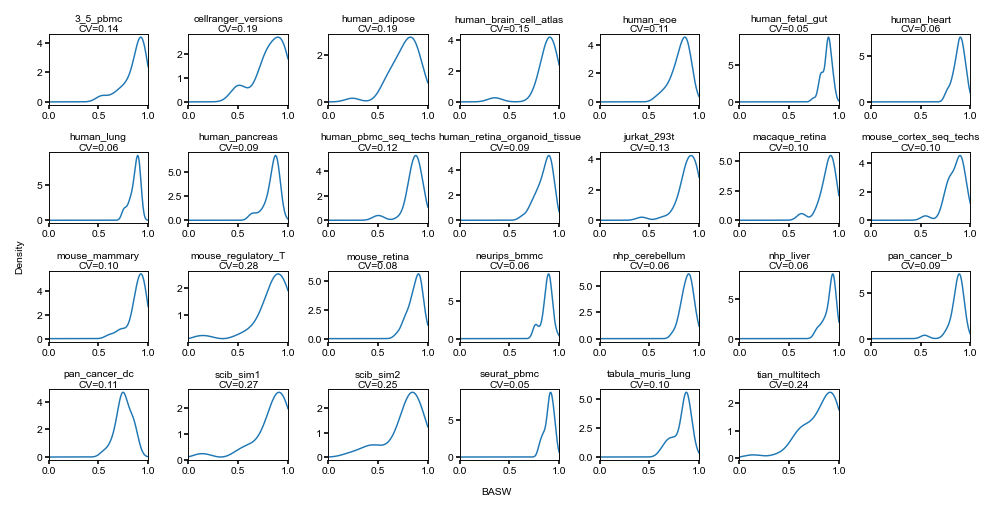

In [10]:
datasets = dataset_corrs['Dataset'].unique()
n_datasets = len(datasets)
n_cols = 7
n_rows = math.ceil(n_datasets / n_cols)
with plt.rc_context({'figure.dpi': 150}):
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(6.5, 3.3), constrained_layout=True)
    axes_flat = axes.flatten()
    for i, ds_name in enumerate(datasets):
        ax = axes_flat[i]
        sub = df_full[(df_full.Metric == metric_a) & (df_full.Dataset == ds_name)]
        x = sub['Value'].dropna().to_numpy()
        ax.tick_params(axis='both', which='major', width=.8, length=2, labelsize=5, pad=1)
        for spine in ax.spines.values():
            spine.set_linewidth(0.45)
        x_grid = np.linspace(0, 1, 200)
        ax.plot(x_grid, scipy.stats.gaussian_kde(x)(x_grid), linewidth=0.7)
        ax.set_title(f'{ds_name}\nCV={cvs.set_index("Dataset").loc[ds_name, metric_a]:.2f}', fontsize=5, pad=0.5)
        ax.set_xlim(0, 1)
    fig.supxlabel(metric_a.upper(), fontweight='bold', fontsize=5)
    fig.supylabel('Density', fontweight='bold', fontsize=5)
    for j in range(i + 1, len(axes_flat)):
        axes_flat[j].axis('off')
#     plt.savefig(f'../publication_figures/{metric_a}_kde.png', dpi=250, bbox_inches='tight')
    plt.show()
    plt.close()

Now, select a specific dataset and just plot the scatterplot for that one dataset.
Each dot represents an integration.

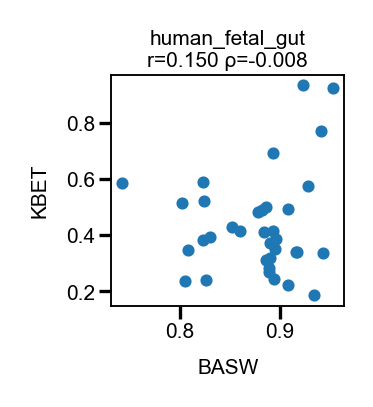

In [9]:
dataset = 'human_fetal_gut'
with plt.rc_context({'figure.figsize': (1, 1), 'figure.dpi': 300}):
    sub = df_full[df_full.Metric.isin([metric_a, metric_b]) & df_full.Dataset.isin([dataset])]
    x = sub[sub.Metric == metric_a]['Value'].to_numpy()
    y = sub[sub.Metric == metric_b]['Value'].to_numpy()
    mask = ~np.isnan(x) & ~np.isnan(y)
    x_valid = x[mask]
    y_valid = y[mask]
    integration_list = sub[sub.Metric == metric_a]['Integration'][mask]

    fig, ax = plt.subplots()
    ax.scatter(x[mask], y[mask], s=2)
#     is_target = (integration_list == 'scanorama-1')
#     ax.scatter(x_valid[~is_target], y_valid[~is_target], s=2, c='C0')
#     ax.scatter(x_valid[is_target], y_valid[is_target], color='red', marker='*', s=5, zorder=3)
    plt.xlabel(metric_a.upper(), fontsize=5)
    plt.ylabel(metric_b.upper(), fontsize=5)
    plt.title(f'{dataset}\nr={scipy.stats.pearsonr(x[mask], y[mask]).statistic:.3f} ρ={scipy.stats.spearmanr(x[mask], y[mask]).statistic:.3f}',
              fontsize=5, pad=2)
    ax.tick_params(axis='both', which='major', width=.8,
                   length=3, 
                   labelsize=5,
                   pad=1)
    for spine in ax.spines.values():
        spine.set_linewidth(0.45)
#     plt.savefig(f'../publication_figures/{dataset}_{metric_a}_{metric_b}.png', dpi=300, bbox_inches='tight')
    plt.show()

Find the integrations where the two metrics disagree the most.

In [16]:
pd.options.display.float_format = '{:.7f}'.format

sub = df_full[df_full['Dataset'] == dataset]
sub = sub[sub.Metric.isin([metric_a, metric_b])]
sub_wide = sub.pivot(index='Integration', columns='Metric', values='Value')
rank_a = sub_wide[metric_a].rank(ascending=False)
rank_b = sub_wide[metric_b].rank(ascending=False)
sub_wide['rank_diff'] = (rank_a - rank_b)
sub_wide.sort_values('rank_diff', ascending=False)

Metric,basw,kbet,rank_diff
Integration,,,
saucie-1,0.7424883,0.5878010,29.0000000
liger-1,0.8235801,0.5905390,25.0000000
ocat-1,0.8024458,0.5140696,25.0000000
respan-1,0.8243991,0.5227303,21.0000000
imap-1,0.8519887,0.4314253,12.0000000
cca-1,0.8231699,0.3838992,11.0000000
portal-1,0.8858255,0.4996136,11.0000000
scdml-1,0.8777779,0.4814834,11.0000000
scanvi-1,0.8819637,0.4887285,11.0000000


## Interrogate a specific integration.

In [22]:
adata = sc.read(f'../data/{dataset}.h5ad')

In [10]:
method = 'harmony'
d = runs[runs.name.str.contains(dataset) & runs.name.str.contains(method)].iloc[0]['workdir']
print(d)
adata_int = sc.read(f"{d}/save_dir/adata.h5ad")
batch_col = adata_int.obs.columns[0]
celltype_col = adata_int.obs.columns[-11]

# if adata_int.X is None:
#     adata_int = ad.AnnData(
#         X=adata.X,
#         obs=adata_int.obs,
#         var=adata.var,
#         uns=adata_int.uns,
#         obsm=adata_int.obsm,
#         varm=adata_int.varm,
#         obsp=adata_int.obsp,
#         varp=adata.varp,
#         layers=adata.layers,
# )
adata_int

/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/work/49/1689f33cc0a8939fe7f39b9e7c1a9e


AnnData object with n_obs × n_vars = 62849 × 33694
    obs: 'Donor_id', 'Organ', 'Sample', 'cell_name_detailed', 'cluster_0.2', 'cluster_0.4', 'cluster_0.6', 'cluster_0.8', 'cluster_1.0', 'cluster_1.2', 'cluster_1.4', 'cluster_1.6', 'cluster_1.8', 'cluster_2.0'
    uns: 'cluster_0.2', 'cluster_0.4', 'cluster_0.6', 'cluster_0.8', 'cluster_1.0', 'cluster_1.2', 'cluster_1.4', 'cluster_1.6', 'cluster_1.8', 'cluster_2.0', 'neighbors'
    obsm: 'X_integration', 'X_umap'
    obsp: 'connectivities', 'distances'

In [ ]:
# UMAP plot just for exploration
sc.pl.umap(adata_int, color=[batch_col, celltype_col], ncols=2, wspace=0.4)

In [ ]:
# PCA plot just for exploration
sc.pl.pca(adata, color=celltype_col, dimensions=[(0, 1), (2, 3), (4, 5), (6, 7), (8, 9), (10, 11), (12, 13)])

Plot the UMAPs for publication figures.

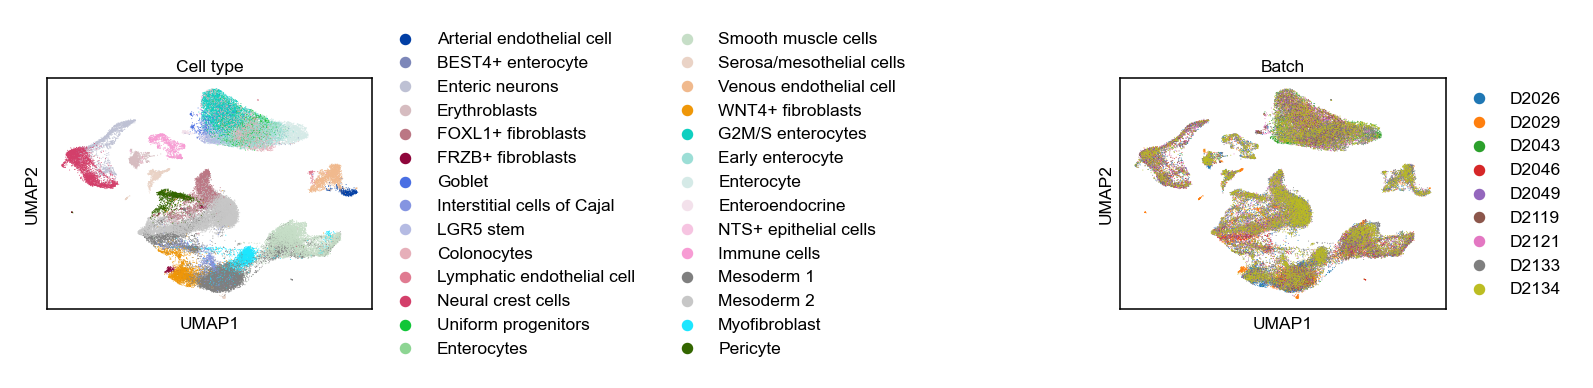

In [13]:
with plt.rc_context({'figure.figsize': (1.2, 1.2), 'figure.dpi': 250, 'legend.markerscale': .2}):
    axs = sc.pl.umap(
        adata_int, 
        color=[celltype_col, batch_col],
#         color=[celltype_col, batch_col, 'cluster_1.0'],
        ncols=3, 
        wspace=2,
        title=['Cell type', 'Batch'], 
#         title=['Cell type', 'Batch', 'Leiden resolution 1.0'],
        legend_fontsize=5,
        size=.3,
        show=False
    )
    frame_thickness = .45
    for ax in axs:
        for spine in ax.spines.values():
            spine.set_linewidth(frame_thickness)
        ax.tick_params(labelsize=5)
        ax.xaxis.label.set_size(5)
        ax.yaxis.label.set_size(5)
        ax.title.set_size(5)
        
        ax.set_xlabel(ax.get_xlabel(), labelpad=2)
        ax.set_ylabel(ax.get_ylabel(), labelpad=2)
        
        ax.set_title(ax.get_title(), pad=2, fontsize=5)
    plt.savefig(f'../publication_figures/{method}_{dataset}_umap.png', dpi=300, bbox_inches='tight')
    plt.show()

In [78]:
batch_counts = adata_int.obs.groupby(celltype_col)[batch_col].nunique()
rare_cell_types = batch_counts[batch_counts == batch_counts.min()].index.tolist()
rare_cell_types

/scratch-ssd/slurm-jobs/yinian/1733573/ipykernel_2633447/68997892.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  batch_counts = adata_int.obs.groupby(celltype_col)[batch_col].nunique()


['t_cell']

## Plots used for Human EoE Supplemental

In [117]:
sc.tl.leiden(adata_int, resolution=1.4, key_added='cluster_1.4__2', random_state=1)

/tmp/ipykernel_935014/298181670.py:1: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(adata_int, resolution=1.4, key_added='cluster_1.4__2', random_state=1)


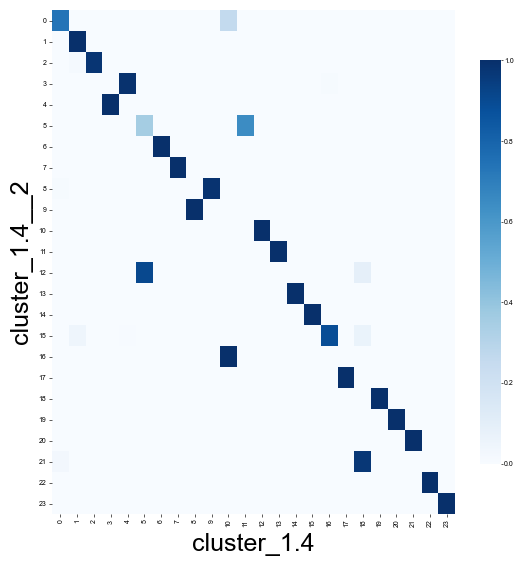

In [119]:
ct = pd.crosstab(adata_int.obs['cluster_1.4__2'], adata_int.obs['cluster_1.4'], normalize='index')

fig, ax = plt.subplots(figsize=(6, 6))
sns.heatmap(ct, cmap='Blues', cbar=True,
            xticklabels=True, yticklabels=True,
            cbar_kws={ 'shrink': 0.8},
            ax=ax)
ax.tick_params(
    axis='both', which='major', width=.45,
    length=2, labelsize=5, pad=2
)

cbar = ax.collections[0].colorbar
cbar.ax.tick_params(
    which='major', width=.45,
    length=1.5, labelsize=5, pad=1
)
# plt.title('Satisfaction Level by Department (Heatmap)')
# plt.xlabel('Leiden clustering', fontsize=5)
# plt.ylabel('Cell type', fontsize=5)
plt.tight_layout()
# plt.savefig('../publication_figures/human_eoe_clustering_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

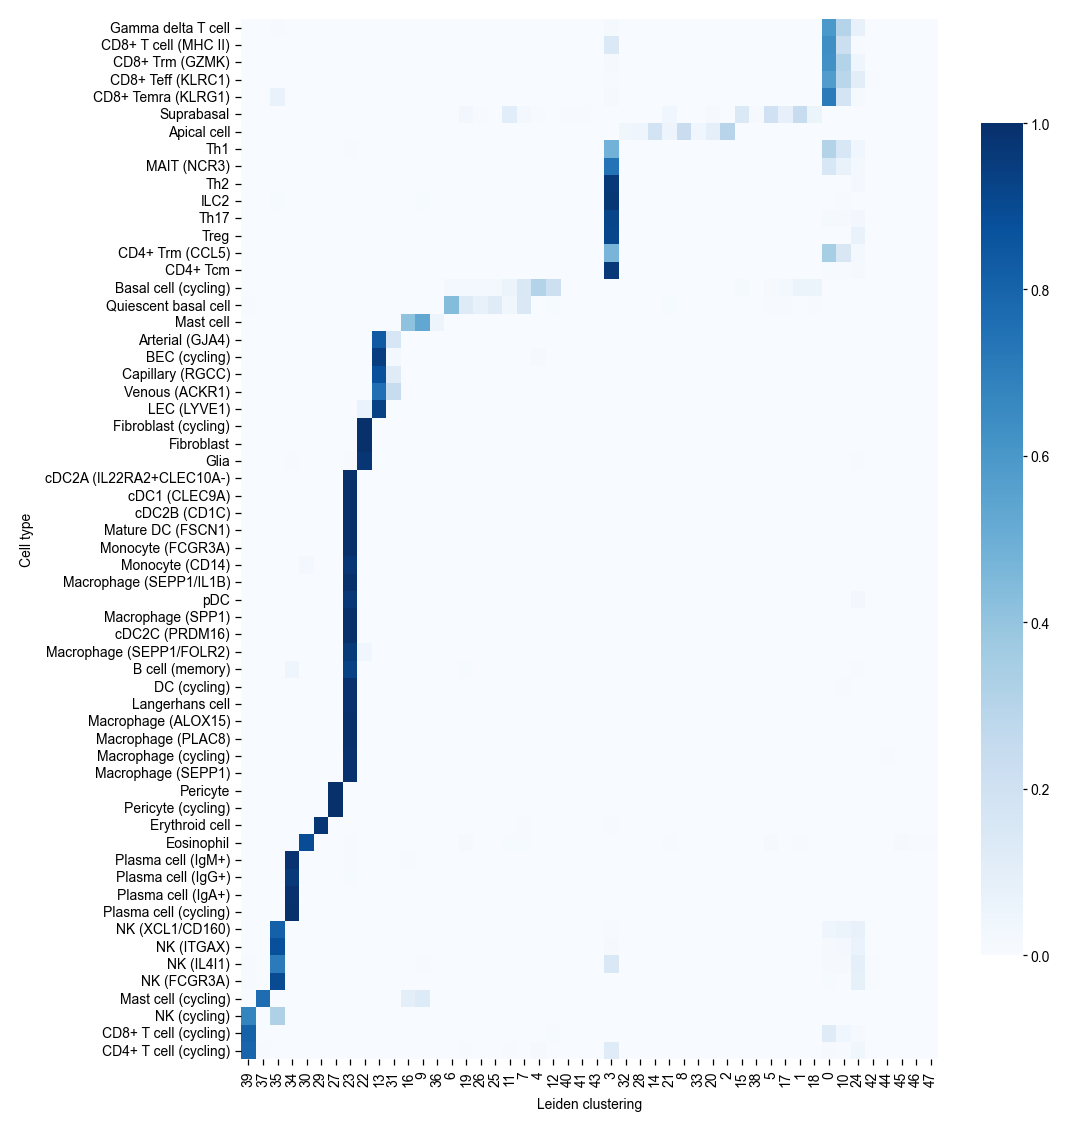

In [68]:
with plt.rc_context({'figure.dpi': 200}):
    ct = pd.crosstab(adata_int.obs[celltype_col], adata_int.obs['cluster_1.8'], normalize='index')

    # sort columns by their argmax row (so clusters group under their dominant cell type)
    col_order = ct.idxmax(axis=0).sort_values().index
    ct_ordered = ct[col_order]

    # sort rows by which column (in the new order) they peak in
    row_order = ct_ordered.idxmax(axis=1).map(lambda c: list(col_order).index(c)).sort_values().index
    ct_ordered = ct_ordered.loc[row_order]
    
    col_order = ['39', '37', '35', '34', '30', '29', '27', '23', '22', '13', '31', '16',
             '9', '36', '6', '19', '26', '25', '11', '7', '4', '12', '40', '41', '43', '3', '32',
             '28', '14', '21', '8', '33', '20', '2', '15', '38', '5', '17', '1', '18', '0', '10', '24', '42', '44', '45', '46', '47']
    ct_ordered = ct_ordered[col_order]

    fig, ax = plt.subplots(figsize=(6, 6))
    sns.heatmap(ct_ordered, cmap='Blues', cbar=True,
                xticklabels=True, yticklabels=True,
                cbar_kws={ 'shrink': 0.8},
                ax=ax)
    ax.tick_params(
        axis='both', which='major', width=.45,
        length=2, labelsize=5, pad=2
    )

    cbar = ax.collections[0].colorbar
    cbar.ax.tick_params(
        which='major', width=.45,
        length=1.5, labelsize=5, pad=1
    )
    # plt.title('Satisfaction Level by Department (Heatmap)')
    plt.xlabel('Leiden clustering', fontsize=5)
    plt.ylabel('Cell type', fontsize=5)
    plt.tight_layout()
    plt.savefig('../publication_figures/human_eoe_clustering_heatmap.png', dpi=300, bbox_inches='tight')
    plt.show()

## Code for cell cycle conservation supplemental

In [149]:
res = cell_cycle(adata, adata_int, batch_key=batch_col, embed='X_integration', agg_func=None, organism='human', n_comps=10)

  0%|          | 0/3 [00:00<?, ?it/s]/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/python3.10/site-packages/scanpy/tools/_score_genes.py:165: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[score_name] = pd.Series(
/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/python3.10/site-packages/scanpy/preprocessing/_pca/__init__.py:227: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  mask_var_param, mask_var = _handle_mask_var(
/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/python3.10/site-packages/scanpy/preprocessing/_pca/__init__.py:227: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through

In [150]:
res

,batch,before,after,score
0,mixture,0.2114997,0.1940040,0.9172782
1,jurkat_pure,0.2187840,0.3401044,0.4454791
2,hek293t_pure,0.1597377,0.2874523,0.2004728


In [224]:
pcr_comparison(adata, adata_int, batch_col, embed='X_integration', n_comps=10)

/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/python3.10/site-packages/scanpy/preprocessing/_pca/__init__.py:227: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  mask_var_param, mask_var = _handle_mask_var(


np.float64(0.9986385038610784)

In [215]:
scib.metrics.pcr.pc_regression(adata.obsm['X_pca'], adata.obs[batch_col])

/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/python3.10/site-packages/scanpy/preprocessing/_pca/__init__.py:227: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  mask_var_param, mask_var = _handle_mask_var(


np.float64(0.16957743672846887)

In [216]:
scib.metrics.pcr.pc_regression(adata_int.obsm['X_integration'], adata_int.obs[batch_col])

/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/python3.10/site-packages/scanpy/preprocessing/_pca/__init__.py:227: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  mask_var_param, mask_var = _handle_mask_var(


np.float64(0.00018867040384460605)

In [129]:
plt.rcdefaults()

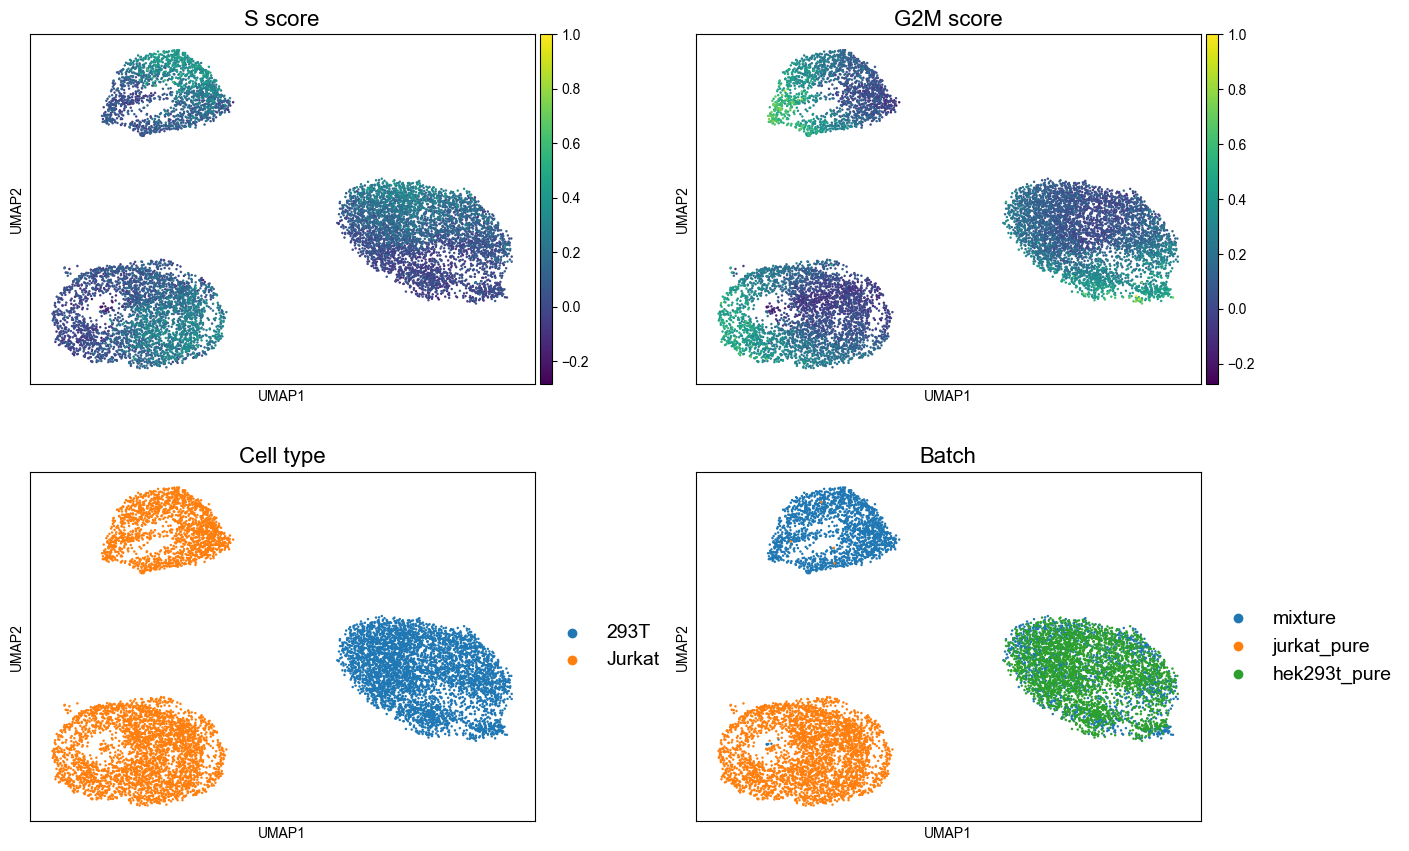

In [155]:
# sc.tl.score_genes_cell_cycle(adata, s_genes=hg_s, g2m_genes=hg_g2m)
with plt.rc_context({'legend.fontsize': 18, 'axes.titlesize': 18}):
    axes = sc.pl.umap(
        adata, 
        color=['S_score', 'G2M_score', celltype_col, batch_col], 
        vmax=1, 
        ncols=4, 
        title=['S score', 'G2M score', 'Cell type', 'Batch'],
        show=False 
    )

    # Move legends to bottom and reduce dot-text spacing
    for ax in axes:
        legend = ax.get_legend()
        if legend is not None:
            handles = legend.legend_handles
            labels = [t.get_text() for t in legend.get_texts()]
            legend.remove()
            ax.legend(
                handles,
                labels,
                loc='upper center',
                bbox_to_anchor=(0.5, -0.05),
                ncol=3,
                frameon=False,
                handletextpad=0.1,  # reduces gap between dot and text
                columnspacing=0.5,  # reduces gap between columns
            )
    
    plt.tight_layout()
    plt.show()

/scratch-ssd/slurm-jobs/yinian/1778040/ipykernel_1121806/3134479442.py:30: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


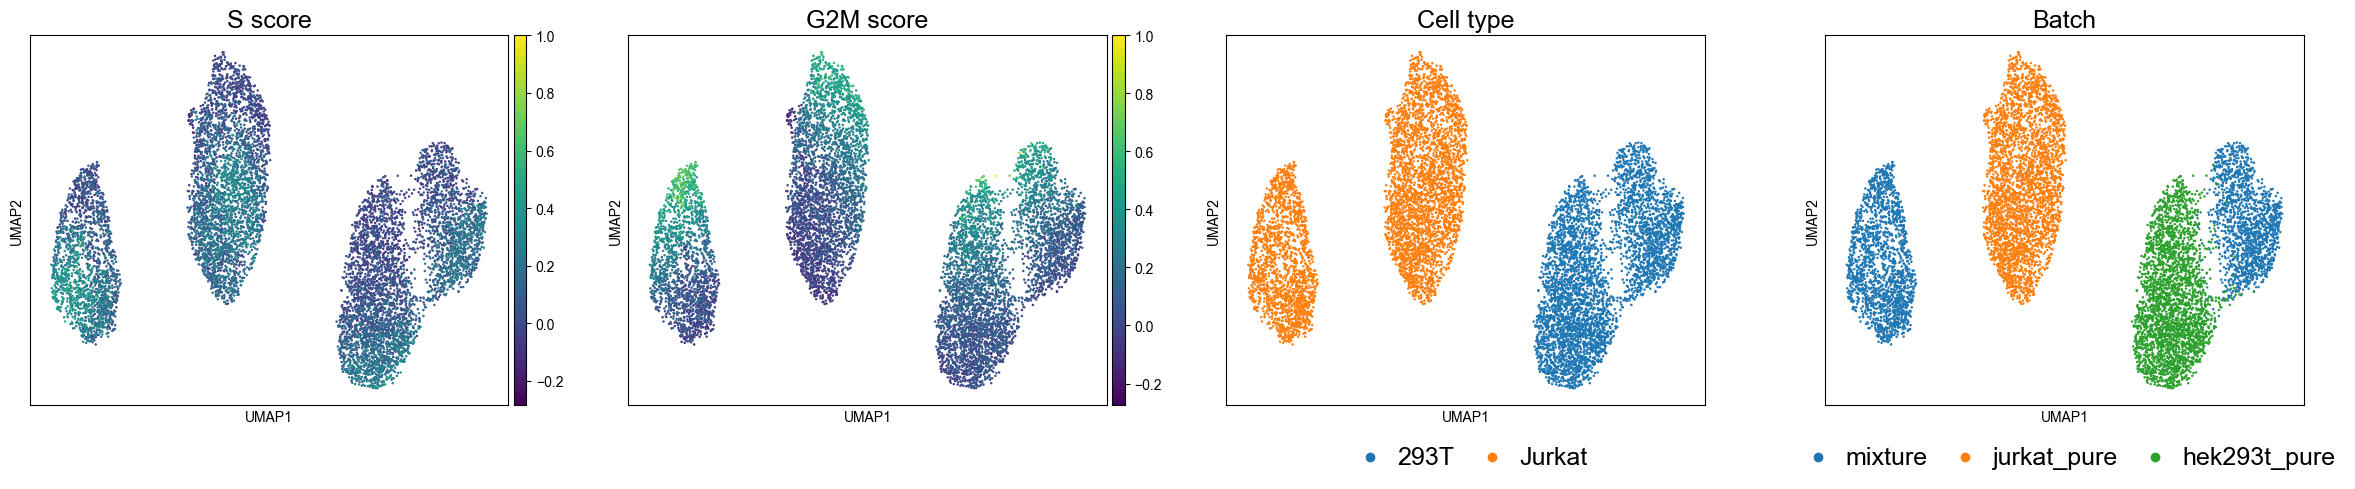

In [172]:
sc.tl.score_genes_cell_cycle(adata_int, s_genes=hg_s, g2m_genes=hg_g2m)
with plt.rc_context({'legend.fontsize': 18, 'axes.titlesize': 18}):
    axes = sc.pl.umap(
        adata_int, 
        color=['S_score', 'G2M_score', celltype_col, batch_col], 
        vmax=1, 
        ncols=4, 
        title=['S score', 'G2M score', 'Cell type', 'Batch'],
        show=False 
    )

    # Move legends to bottom and reduce dot-text spacing
    for ax in axes:
        legend = ax.get_legend()
        if legend is not None:
            handles = legend.legend_handles
            labels = [t.get_text() for t in legend.get_texts()]
            legend.remove()
            ax.legend(
                handles,
                labels,
                loc='upper center',
                bbox_to_anchor=(0.5, -0.05),
                ncol=3,
                frameon=False,
                handletextpad=0.1,  # reduces gap between dot and text
                columnspacing=0.5,  # reduces gap between columns
            )
    
    plt.tight_layout()
    plt.show()

## Other testing of metrics (ignore)

In [33]:
res = scib.metrics.sub_variable_genes(adata, 'cell_ontology_id', batch_col, 500, 0.7)

/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scib/scib/metrics/morans_i.py:142: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  groups = adata.obs.groupby([label_key, batch_key]).size()


571 5054
1758 4760
507 3215


In [44]:
res[1]['genes']

Dcn         0.865834
Lum         0.852672
Ndufa4l2    0.903824
Serpinf1    0.875256
Ccl11       0.852968
Igfbp4      0.861433
Aspn        0.880281
Mustn1      0.881670
Scara5      0.857540
Enpp2       0.862658
Ly6a        0.911036
Pi16        0.906940
Malat1      0.908631
Gsn         0.869200
Gucy1b3     0.864998
Npnt        0.861078
Macf1       0.868935
Limch1      0.861647
Inmt        0.936869
Mgp         0.851839
Hhip        0.939730
Clec3b      0.851246
Name: morans_i, dtype: float64

In [249]:
crossfold_logistic(adata_int, celltype_col, 'X_integration')

0.5326825367326136

In [99]:
clisi_score = clisi_graph(
    adata_int,
    batch_key=batch_col,
    label_key=celltype_col,
    type_="knn",
    n_cores=1,
    verbose=True
)

/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scib/scib/metrics/lisi.py:172: UserWarning: 'batch_key' is deprecated and will be ignore
  warnings.warn("'batch_key' is deprecated and will be ignore", stacklevel=1)


using precomputed kNN graph
Convert nearest neighbor matrix and distances for LISI.
Compute knn on shortest paths
call /ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scib/scib/knn_graph/knn_graph.o /scratch-ssd/slurm-jobs/yinian/1590178/lisi_6xzpg737/graph_lisi_input.mtx /scratch-ssd/slurm-jobs/yinian/1590178/lisi_6xzpg737/graph_lisi 90 1 100
LISI score estimation


In [195]:
trajectory_conservation(adata, adata_int, 'cell_type')

/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scib/scib/metrics/trajectory.py:120: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  n_components, adata_post.obs["neighborhood"] = connected_components(
/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scib/scib/metrics/trajectory.py:124: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  start_clust = adata_pre.obs.groupby(ct_key)[pseudotime_key].mean().idxmin()
/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/python3.10/site-packages/scanpy/tools/_dpt.py:25: ImplicitModificationWarning: Setting element `.obsm['X_diffmap']` of view, initializing view as actual.
  adata.obsm["X_diffmap"] = dpt.eigen_basis
/ubc/cs/research/beaver/projects/Single-ce

np.float64(0.5482029303328682)

In [129]:
_, ari_score = cluster_optimal_resolution(
    adata_int, label_key=batch_col, cluster_key='cluster', metric=batch_ari
)
ari_score

resolution: 0.2, batch_ari: 0.782567543921814
resolution: 0.4, batch_ari: 0.8226705583618638
resolution: 0.6, batch_ari: 0.8594609482429456
resolution: 0.8, batch_ari: 0.8742165354935454
resolution: 1.0, batch_ari: 0.8898409940875929
resolution: 1.2, batch_ari: 0.8958510202660106
resolution: 1.4, batch_ari: 0.9005750782983348
resolution: 1.6, batch_ari: 0.91119267653766
resolution: 1.8, batch_ari: 0.913342673270765
resolution: 2.0, batch_ari: 0.9215799902083992
optimised clustering against Batch
optimal cluster resolution: 2.0
optimal score: 0.9215799902083992


/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scib/scib/metrics/batch_ari.py:33: DeprecationWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, pd.CategoricalDtype) instead
  if not pd.api.types.is_categorical_dtype(clusters):
/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scib/scib/metrics/batch_ari.py:35: DeprecationWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, pd.CategoricalDtype) instead
  if not pd.api.types.is_categorical_dtype(batches):
/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scib/scib/metrics/batch_ari.py:33: DeprecationWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, pd.CategoricalDtype) instead
  if not pd.api.types.is_categorical_dtype(clusters):
/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scib/scib/metrics/batch_ari.py:35

0.9215799902083992

In [293]:
_, bari_score = cluster_optimal_resolution(
    adata_int, label_key=celltype_col, cluster_key='cluster', metric=f1_score_macro
)
bari_score

resolution: 0.2, f1_score_macro: 0.585759421420277
resolution: 0.4, f1_score_macro: 0.6839886905565224
resolution: 0.6, f1_score_macro: 0.6843873827543179
resolution: 0.8, f1_score_macro: 0.6840447795690654
resolution: 1.0, f1_score_macro: 0.6839184544170211
resolution: 1.2, f1_score_macro: 0.6841913600253546
resolution: 1.4, f1_score_macro: 0.6830288182886295
resolution: 1.6, f1_score_macro: 0.6834463387015597
resolution: 1.8, f1_score_macro: 0.6837128564629564
resolution: 2.0, f1_score_macro: 0.6837984144742661
optimised clustering against Celltype
optimal cluster resolution: 0.6
optimal score: 0.6843873827543179


/scratch-ssd/slurm-jobs/yinian/1724214/ipykernel_82041/109313695.py:1: UserWarning: Overwriting existing key cluster in adata.obs
  _, bari_score = cluster_optimal_resolution(


0.6843873827543179

In [99]:
res = silhouette_batch(adata_int, batch_col, celltype_col, 'X_integration', return_all=True)

mean silhouette per group:                           silhouette_score
group                                     
Apical cell                       0.893860
Arterial (GJA4)                   0.900799
B cell (memory)                   0.837159
BEC (cycling)                     0.793377
Basal cell (cycling)              0.906899
CD4+ T cell (cycling)             0.840779
CD4+ Tcm                          0.902438
CD4+ Trm (CCL5)                   0.882003
CD8+ T cell (MHC II)              0.882161
CD8+ T cell (cycling)             0.869084
CD8+ Teff (KLRC1)                 0.899135
CD8+ Temra (KLRG1)                0.885893
CD8+ Trm (GZMK)                   0.896983
Capillary (RGCC)                  0.900164
DC (cycling)                      0.796759
Eosinophil                        0.879119
Erythroid cell                    0.893134
Fibroblast                        0.875919
Fibroblast (cycling)              0.874195
Gamma delta T cell                0.888658
Glia                       

In [105]:
res[1]

,silhouette_score
group,
Apical cell,0.893860
Arterial (GJA4),0.900799
B cell (memory),0.837159
BEC (cycling),0.793377
Basal cell (cycling),0.906899
CD4+ T cell (cycling),0.840779
CD4+ Tcm,0.902438
CD4+ Trm (CCL5),0.882003
CD8+ T cell (MHC II),0.882161


In [398]:
X = np.array([x[mask], y[mask]]).T

robust_cov = MinCovDet().fit(X)
distances = robust_cov.mahalanobis(X)

threshold = chi2.ppf(0.975, df=2)
outliers = distances > threshold

# 3. Create a ranked DataFrame
results = pd.DataFrame({
    'index': range(len(x[mask])),
    'coords': list(zip(x[mask], y[mask])),
    'm_distance': distances,
    'integration': integration_list,
    'outlier': outliers
})

# Sort by distance (highest first)
ranked_outliers = results.sort_values(by='m_distance', ascending=False)
ranked_outliers.head(20)

,index,coords,m_distance,integration,outlier
31680,14,"(0.003289493344935, 0.0645784915153905)",29.728349,oneBigBlob-1,True
50328,21,"(0.942850498395308, 0.5948182579895229)",23.910430,scanvi-1,True
6816,3,"(1.0, 0.7077568172299393)",22.135046,equidistant-1,True
21320,9,"(0.999803627361666, 0.7448025199369761)",20.138536,islander-1,True
8888,4,"(0.2756941468991219, 0.8297813116938288)",15.497319,gedi-1,True
27536,12,"(0.1856065933750819, 0.2258565233891738)",15.351715,mnn-1,True
29608,13,"(0.6126081115738504, 0.4008867215259766)",12.484820,ocat-1,True
17176,8,"(0.2201948992079784, 0.483884527097267)",7.013430,imap-1,False
77264,33,"(0.5932853723630868, 0.4824481033212634)",6.375590,sysvi-1,False
64832,28,"(0.3732232883639435, 0.4334816927381232)",4.398249,scmerge-1,False


In [69]:
adata_int.obsm['X_integration']

array([[-0.1199092 , -0.06683245, -0.13253945, ...,  0.14767218,
         0.07731985, -0.11729085],
       [-0.2669993 , -0.1965689 ,  0.49963245, ...,  0.44943264,
        -0.04368195, -0.04174643],
       [-0.08113198, -0.12963586,  0.44516283, ...,  0.42817935,
        -0.12678835, -0.17317224],
       ...,
       [-0.12898941, -0.4028506 , -0.31644127, ..., -0.1029664 ,
        -0.19333671,  0.10311589],
       [-0.0755432 ,  0.1533028 ,  0.227288  , ...,  0.22025421,
        -0.18949631, -0.00438526],
       [ 0.05631804, -0.00715081,  0.23028442, ...,  0.02273415,
        -0.05463511,  0.18932888]], shape=(90261, 50), dtype=float32)

In [15]:
cilisi(adata_int, batch_col, celltype_col, embed='X_integration')

Chunk 1 does not have enough neighbors. Skipping...
Chunk 2 does not have enough neighbors. Skipping...
Chunk 3 does not have enough neighbors. Skipping...
Chunk 4 does not have enough neighbors. Skipping...
Chunk 5 does not have enough neighbors. Skipping...
Chunk 6 does not have enough neighbors. Skipping...
Chunk 7 does not have enough neighbors. Skipping...
Chunk 8 does not have enough neighbors. Skipping...
Chunk 9 does not have enough neighbors. Skipping...
Chunk 10 does not have enough neighbors. Skipping...
Chunk 11 does not have enough neighbors. Skipping...
Chunk 12 does not have enough neighbors. Skipping...
Chunk 13 does not have enough neighbors. Skipping...
Chunk 14 does not have enough neighbors. Skipping...
Chunk 15 does not have enough neighbors. Skipping...
Chunk 16 does not have enough neighbors. Skipping...
Chunk 17 does not have enough neighbors. Skipping...
Chunk 18 does not have enough neighbors. Skipping...
Chunk 19 does not have enough neighbors. Skipping...
Ch

np.float64(0.2850322343402111)

In [206]:
sil = sklearn.metrics.silhouette_samples(adata_int.obsm["X_integration"], adata_int.obs[celltype_col])

In [201]:
adata_int[adata_int.obs[celltype_col] == 'basal'].obsm['X_integration'].mean(axis=0)

array([-2.8435178e-02, -9.5702866e-03,  5.8172704e-03, -1.5299508e-04,
        1.0496137e+00, -2.8451914e-03, -3.9033759e-02,  8.8845366e-01,
        4.8443582e-02, -7.2359279e-02], dtype=float32)

In [202]:
adata_int[adata_int.obs[celltype_col] == 'luminal_progenitor'].obsm['X_integration'].mean(axis=0)

array([ 0.02922621,  0.09412994, -0.00273393,  0.11111067, -1.1964817 ,
       -0.02595729, -0.03981369,  0.6432533 , -0.01790497, -0.09695376],
      dtype=float32)

In [205]:
adata_int[adata_int.obs[celltype_col] == 'luminal_mature'].obsm['X_integration'].mean(axis=0)

array([ 0.03195745,  0.02533594, -0.01671697, -0.01734718,  0.01705251,
       -0.00579024, -0.00208784, -1.0226662 , -0.03306956,  0.0701558 ],
      dtype=float32)